# 09 · Waves, strings and beams

Second-order-in-time equations - the wave equation, vibrating strings, bending beams - are either rewritten as
first-order systems [u, v] and handed to any integrator, or integrated directly by Stormer-Verlet, which
preserves energy over long times. Their spectra are purely imaginary (undamped) or shifted left by damping;
their stiffness comes from the spatial operator's largest frequency: 2c/Δx for a string, 4/Δx² for a beam.
This notebook checks standing waves against exact solutions, watches energy under different integrators, and
handles damping and a moving load.

**What you will learn**
- integrate second-order wave equations as first-order systems and with Stormer-Verlet
- monitor energy and recognise numerical damping
- relate the stiffness of strings and beams to their operators
- treat damping and moving loads

**Before you start:** notebooks 02 and 09 of engnumeric help  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engmolines is missing): install it from GitHub
    import engmolines
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engmolines"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engmolines import problems as pr, integrators as ti, analysis, stiffness
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The vibrating string: RK4 versus Stormer-Verlet

RK4 (first-order system)  : energy change after 20 periods +3.69e-07; position error 2.1e-04
Stormer-Verlet            : energy change after 20 periods +1.78e-07; position error 1.2e-04
BDF2 (dissipative)        : energy change after 20 periods -1.94e-03; position error 2.9e-03


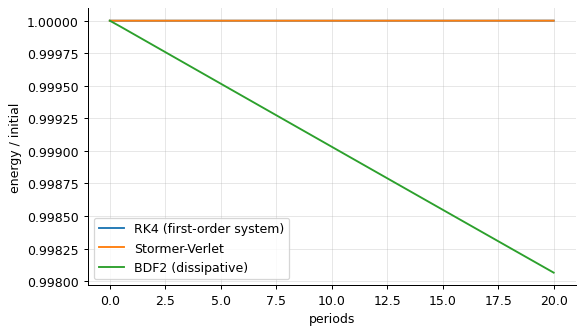

In [2]:
p = pr.wave_string(mode=2)
n = 101
T = p.t_end
runs = {"RK4 (first-order system)": ti.explicit_rk(p.rhs, p.y0, (0, 20 * T), 0.005, n_out=40),
        "Stormer-Verlet": ti.verlet(p.params["accel"], p.y0[:n], p.y0[n:], (0, 20 * T), 0.005, n_out=40),
        "BDF2 (dissipative)": ti.bdf(p.rhs, p.y0, (0, 20 * T), 0.005, 2, band=(n + 1, n + 1), n_out=40)}
for name, s in runs.items():
    E = np.array([analysis.wave_energy(y[:n], y[n:], 1.0, p.grid) for y in s.y])
    plt.plot(s.t / T, E / E[0], label=name)
    print(f"{name:<26}: energy change after 20 periods {E[-1] / E[0] - 1:+.2e}; position error {np.max(np.abs(s.y[-1][:n] - p.exact(p.x, s.t[-1]))):.1e}")
plt.xlabel("periods"); plt.ylabel("energy / initial"); plt.legend(); plt.show()

Over twenty periods RK4's numerical damping is invisible at this step - |R(ihω)| deviates from 1 only at
order (hω)⁶, and hω = 0.03 for the mode present - while BDF2, built for stiff dissipative problems, damps the
wave by 0.2 % and lags it. At this step neither RK4 nor Verlet changes the energy measurably (the 10⁻⁷ is the
discretisation error of the energy sum itself). The difference between them appears over very long runs or at
larger steps: Verlet is symplectic and keeps the energy bounded for any length of run, while RK4's small
dissipation accumulates (the exercises test this). For undamped waves, the right integrators are the ones
made for them.

## Spectra: strings, beams and stiffness

In [3]:
ps = pr.wave_string(); lam_s = stiffness.spectrum(ps.rhs, ps.y0)
pb = pr.beam_vibration(); lam_b = stiffness.spectrum(pb.rhs, pb.y0)
print(f"string: |lambda|max = {np.max(np.abs(lam_s.imag)):.0f} = 2c/dx = {2 / ps.grid.dx:.0f} (period of the fastest grid mode / period of the solution = {np.max(np.abs(lam_s.imag)) / (2 * np.pi / ps.t_end):.0f})")
print(f"beam:   |lambda|max = {np.max(np.abs(lam_b.imag)):.0f} = 4 sqrt(EI/rhoA)/dx^2 = {4 / pb.grid.dx**2:.0f} (ratio {np.max(np.abs(lam_b.imag)) / pb.params['omega']:.0f}): the beam is far stiffer")
sv = ti.verlet(pb.params["accel"], pb.y0[:61], pb.y0[61:], (0, pb.t_end), 0.4 * pb.grid.dx**2, n_out=1)
print(f"Verlet on the beam at h = 0.4 dx^2 (limit dx^2/2): error after one period {np.max(np.abs(sv.y[-1][:61] - pb.exact(pb.x, pb.t_end))):.1e}; steps {sv.steps}")

string: |lambda|max = 200 = 2c/dx = 200 (period of the fastest grid mode / period of the solution = 32)
beam:   |lambda|max = 14390 = 4 sqrt(EI/rhoA)/dx^2 = 14400 (ratio 1458): the beam is far stiffer


Verlet on the beam at h = 0.4 dx^2 (limit dx^2/2): error after one period 1.0e-06; steps 5730


The string's grid modes oscillate 60 times faster than its solution; the beam's 1400 times, because the
biharmonic operator's largest eigenvalue scales as Δx⁻⁴ and frequencies as its square root. Verlet's limit
h ω_max ≤ 2 then forces h ≤ Δx²/2 - 6000 steps for one period of the first mode. Implicit methods exist for
such problems (Newmark's family, the trapezoidal rule with its ringing), but for an accurate undamped
long-time solution the explicit symplectic method with its small step is often the honest choice.

## Damping: the telegraph equation

every dynamic eigenvalue has real part [-0.5] = -a


RK4: error vs e^(-at) sin(pi x) cos(omega t) = 1.1e-05


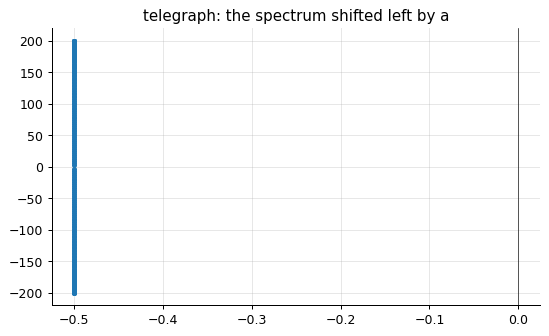

In [4]:
p = pr.telegraph(a=0.5)
lam = stiffness.spectrum(p.rhs, p.y0); lam = lam[np.abs(lam) > 1e-9]
print(f"every dynamic eigenvalue has real part {np.unique(np.round(lam.real, 6))} = -a")
s = p.solve("rk4", 0.005, n_out=1)
print(f"RK4: error vs e^(-at) sin(pi x) cos(omega t) = {p.error(s):.1e}")
plt.plot(lam.real, lam.imag, "."); plt.axvline(0, color="k", lw=0.5); plt.title("telegraph: the spectrum shifted left by a"); plt.show()

Damping shifts the whole spectrum left by a, so every mode decays at the same rate and the oscillation
frequencies become √(c²k² − a²). With dissipation present the choice of integrator is less delicate: RK4 is
accurate, and a dissipative implicit method would add only a little to the physical damping.

## A moving load

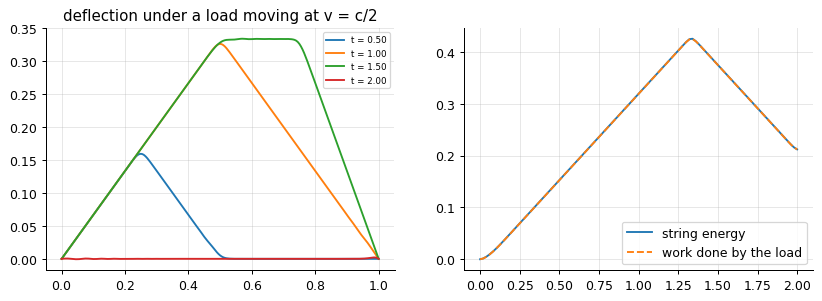

energy balance: max |E - W| / max E = 0.002


In [5]:
p = pr.string_moving_load(v=0.5)
s = p.solve("rk4", 0.001, n_out=100)
n = 201
E = np.array([analysis.wave_energy(y[:n], y[n:], 1.0, p.grid) for y in s.y])
power = np.array([p.grid.integrate(p.params["load"](t) * y[n:]) for t, y in zip(s.t, s.y)])
work = np.r_[0.0, np.cumsum(0.5 * (power[1:] + power[:-1]) * np.diff(s.t))]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for i in (25, 50, 75, 100):
    axes[0].plot(p.x, s.y[i][:n], label=f"t = {s.t[i]:.2f}")
axes[0].legend(fontsize=7); axes[0].set_title("deflection under a load moving at v = c/2")
axes[1].plot(s.t, E, label="string energy"); axes[1].plot(s.t, work, "--", label="work done by the load"); axes[1].legend(); plt.show()
print(f"energy balance: max |E - W| / max E = {np.max(np.abs(E - work)) / E.max():.3f}")

A load crossing a string at half the wave speed leaves waves behind it; the energy the string gains equals the
work the load does, integral F w_t dt at the load's position - a check that the forcing, the energy
bookkeeping and the integrator are all consistent (to 1 % here, the error of the trapezoid rule on the power
history).

## Inside the algorithm: one Verlet step

In [6]:
u_, v_ = ps.y0[:101].copy(), ps.y0[101:].copy(); h_ = 0.005
a_ = ps.params["accel"](0.0, u_)
v_half = v_ + 0.5 * h_ * a_
u_ = u_ + h_ * v_half
v_ = v_half + 0.5 * h_ * ps.params["accel"](h_, u_)
lib = ti.verlet(ps.params["accel"], ps.y0[:101], ps.y0[101:], (0, h_), h_, n_out=1).y[-1]
print("one step by hand vs library:", np.max(np.abs(np.r_[u_, v_] - lib)))

one step by hand vs library: 0.0


## Exercises
1. Integrate the string with the trapezoidal rule (A-stable, non-dissipative) for 20 periods: is the energy conserved? Is the phase correct? Compare with Verlet at the same step.
2. Give the beam a clamped left end and a free right end (`biharmonic(w, g, 'clamped', 'free')`) and find its first natural frequency from a long integration (the FFT of the tip displacement); compare with (1.875)^2 sqrt(EI/rhoA)/L^2.
3. **Implement it yourself:** write the energy-conserving Verlet step for the wave equation with a damping term -2 a v (treat the damping implicitly in the velocity update) and verify the decay rate against the telegraph solution.